# BT4012 Group 2 — Data Preparation and Feature Engineering
**Data preparation owner: Kang Min Gu**  
**Dataset: IBM AML HI-Small**

This notebook loads the two source files, cleans transactions, constructs features, maps evaluation labels, creates a chronological 70/15/15 split, and checks the saved files. All implementation code is included here. Run cells from top to bottom from the repository root or its notebooks folder; Python 3.12 and the packages in `requirements-data.txt` were used.

**Final outputs:** `data/processed/train.csv`, `validation.csv`, `test.csv`, and `pattern_labels.csv`. The first three include the model features and binary target. The fourth contains evaluation-only typology annotations. No model is trained in this notebook.

Data sources: [Kaggle IBM AML](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml), [IBM dataset description](https://github.com/IBM/AML-Data). The data is synthetic; IBM identifies the data license as CDLA-Sharing-1.0. Code development and review were assisted by OpenAI Codex; submitted work should acknowledge this assistance.

## 1. Imports and working folder
Only standard libraries and installed packages are imported. There are no local Python-module dependencies. The complete run processes approximately five million transactions and needs several GB of memory and disk space.

In [1]:
from pathlib import Path
import hashlib
import time
import gc
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from numba import njit
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW_DIR = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed"
assert all((RAW_DIR / name).is_file() for name in ["HI-Small_Trans.csv", "HI-Small_Patterns.txt"]), "Place both HI-Small source files in data/raw and run from the repo root or notebooks folder."
pd.set_option("display.max_columns", 12)
started_at = time.perf_counter()

## 2. Data loading
### 2.1 Load the transaction CSV
Read the source directly with `pd.read_csv`. Initially reading fields as text preserves bank/account IDs (including meaningful leading zeros) and exact monetary strings for pattern matching. `string[pyarrow]` reduces memory use. Amounts and timestamps are converted explicitly in Section 3.

The source header repeats `Account`; pandas names the second occurrence `Account.1` (the receiving account).

In [2]:
raw = pd.read_csv(RAW_DIR / "HI-Small_Trans.csv", dtype="string[pyarrow]", keep_default_na=False)
raw_columns = raw.columns.tolist()
raw_row_count = len(raw)
raw_positive_count = int(raw["Is Laundering"].eq("1").sum())
print(f"Transactions: {raw_row_count:,}; laundering labels: {raw_positive_count:,}")
display(raw.head())

Transactions: 5,078,345; laundering labels: 5,177


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:20,010,8000EBD30,010,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,03208,8000F4580,001,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,03209,8000F4670,03209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022/09/01 00:02,012,8000F5030,012,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022/09/01 00:06,010,8000F5200,010,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


### 2.2 Inspect the pattern source and record provenance
`Patterns.txt` consists of laundering-attempt blocks containing original transaction rows. Section 5 parses and maps these blocks. SHA256 hashes identify the exact input files used; they are displayed in this notebook instead of creating a separate manifest.

In [3]:
with open(RAW_DIR / "HI-Small_Patterns.txt", encoding="utf-8") as handle:
    pattern_preview = [next(handle).rstrip() for _ in range(5)]
print("\n".join(pattern_preview))

def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

raw_source_hashes = {name: file_sha256(RAW_DIR / name)
                     for name in ["HI-Small_Trans.csv", "HI-Small_Patterns.txt"]}
display(pd.Series(raw_source_hashes, name="SHA256").to_frame())

BEGIN LAUNDERING ATTEMPT - FAN-OUT:  Max 16-degree Fan-Out
2022/09/01 00:06,021174,800737690,012,80011F990,2848.96,Euro,2848.96,Euro,ACH,1
2022/09/01 04:33,021174,800737690,020,80020C5B0,8630.40,Euro,8630.40,Euro,ACH,1
2022/09/01 09:14,021174,800737690,020,80006A5E0,35642.49,Yuan,35642.49,Yuan,ACH,1
2022/09/01 09:56,021174,800737690,00220,8007A5B70,5738987.96,US Dollar,5738987.96,US Dollar,ACH,1


,SHA256
HI-Small_Trans.csv,b19d39f515523373f991b689c07e11e7b0b95c17a2c27a...
HI-Small_Patterns.txt,2c546b5ce6009e73851f0139af053cf845f08bf92f3bc8...


## 3. Data inspection and cleaning
### 3.1 Missing values, labels and exact duplicates
Check all raw fields before changing their types. Remove only exact duplicate excess rows, using all eleven original fields and retaining the first source occurrence. Since the source has no native event ID, this is a documented deduplication assumption: identical rows cannot be proved to be ingestion errors. Other repeated transfers and self-transfers are retained.

In [4]:
assert raw_columns == ['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']
missing_counts = (raw.isna() | raw.eq("")).sum()
assert missing_counts.sum() == 0, "Review missing values before proceeding."
assert raw["Is Laundering"].isin(["0", "1"]).all()

# Identical observed fields must not carry contradictory targets.
observed_columns = raw_columns[:-1]
possible_conflicts = raw[raw.duplicated(observed_columns, keep=False)]
if len(possible_conflicts):
    assert possible_conflicts.groupby(observed_columns)["Is Laundering"].nunique().max() == 1

duplicate_mask = raw.duplicated(raw_columns, keep="first")
duplicate_rows = raw.loc[duplicate_mask].copy()
duplicate_rows.insert(0, "source_row", duplicate_rows.index + 1)
print("Missing values:", int(missing_counts.sum()))
print("Exact duplicate excess rows removed:", int(duplicate_mask.sum()))
display(duplicate_rows)

# Keep exact positive source strings for the evaluation-label join in Section 5.
positive_raw = raw.loc[raw["Is Laundering"].eq("1")].copy()
positive_raw["source_row"] = positive_raw.index + 1
positive_raw["tx_id"] = positive_raw["source_row"].map(lambda row: f"HI-Small:{row:08d}")

df = raw.loc[~duplicate_mask].copy()
df["source_row"] = df.index.to_numpy() + 1
df["tx_id"] = pd.Series([f"HI-Small:{row:08d}" for row in df["source_row"]],
                         index=df.index, dtype="string[pyarrow]")
removed_duplicate_count = int(duplicate_mask.sum())
del raw, possible_conflicts, duplicate_mask
gc.collect()

Missing values: 0
Exact duplicate excess rows removed: 9


,source_row,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
863295,863296,2022/09/01 16:20,012004,800C927C1,012004,800C927C0,0.000008,Bitcoin,0.08,Euro,ACH,0
863296,863297,2022/09/01 16:20,012004,800C927C1,0220,813D8C1E1,0.000008,Bitcoin,0.000008,Bitcoin,Bitcoin,0
3684005,3684006,2022/09/07 21:25,029992,8099A29B1,0220,813725AE1,0.000003,Bitcoin,0.000003,Bitcoin,Bitcoin,0
4166786,4166787,2022/09/08 21:05,0113779,811144AB1,0113779,811144AB0,0.000002,Bitcoin,0.02,US Dollar,ACH,0
4166787,4166788,2022/09/08 21:05,0113779,811144AB1,0053744,813C777F1,0.000002,Bitcoin,0.000002,Bitcoin,Bitcoin,0
4510480,4510481,2022/09/09 10:03,006075,80C702911,006075,80C702910,0.000002,Bitcoin,0.02,US Dollar,ACH,0
4510481,4510482,2022/09/09 10:03,006075,80C702911,0154653,814389B61,0.000002,Bitcoin,0.000002,Bitcoin,Bitcoin,0
4816512,4816513,2022/09/09 21:33,014433,80935A891,014433,80935A890,0.000001,Bitcoin,0.01,US Dollar,ACH,0
4816513,4816514,2022/09/09 21:33,014433,80935A891,0015,813F7AE61,0.000001,Bitcoin,0.000001,Bitcoin,Bitcoin,0


0

### 3.2 Rename fields and convert timestamps, amounts and target
Transaction IDs depend on the original one-based data row, not the later chronological order. Their source is fixed by the input hash. Preserve amounts as `float64`; do not round Bitcoin amounts to two decimal places. The source supplies no timezone, so timestamps remain timezone-naive.

In [5]:
df = df.rename(columns={'Timestamp': 'timestamp',
 'From Bank': 'from_bank',
 'Account': 'from_account',
 'To Bank': 'to_bank',
 'Account.1': 'to_account',
 'Amount Received': 'amount_received',
 'Receiving Currency': 'receiving_currency',
 'Amount Paid': 'amount_paid',
 'Payment Currency': 'payment_currency',
 'Payment Format': 'payment_format',
 'Is Laundering': 'is_laundering'})
df["timestamp"] = pd.to_datetime(df["timestamp"], format="%Y/%m/%d %H:%M", errors="raise")
for column in ["amount_paid", "amount_received"]:
    df[column] = pd.to_numeric(df[column], errors="raise").to_numpy(dtype=np.float64)
    assert np.isfinite(df[column]).all() and df[column].gt(0).all()
df["is_laundering"] = df["is_laundering"].astype("uint8")
categorical_features = ["payment_currency", "receiving_currency", "payment_format"]
for column in categorical_features:
    df[column] = df[column].astype("category")
assert df["tx_id"].is_unique
assert len(df) + removed_duplicate_count == raw_row_count
assert int(df["is_laundering"].sum()) == raw_positive_count
display(df.dtypes.to_frame("dtype"))

,dtype
timestamp,datetime64[ns]
from_bank,string[pyarrow]
from_account,string[pyarrow]
to_bank,string[pyarrow]
to_account,string[pyarrow]
amount_received,float64
receiving_currency,category
amount_paid,float64
payment_currency,category
payment_format,category


### 3.3 Check currency/amount consistency
Different payment and receiving currencies can legitimately have different amounts. Preserve both sides; no exchange-rate source is available for reliable conversion. Compare paid versus received amounts only when their currencies match.

In [6]:
same_currency = df["payment_currency"].astype(str).eq(df["receiving_currency"].astype(str))
unequal_amount = df["amount_paid"].ne(df["amount_received"])
currency_checks = pd.Series({
    "Cross-currency transactions": int((~same_currency).sum()),
    "Same-currency amount mismatches": int((same_currency & unequal_amount).sum()),
    "Cross-currency amounts numerically equal": int((~same_currency & ~unequal_amount).sum())
})
display(currency_checks.to_frame("rows"))
assert not (same_currency & unequal_amount).any()
del same_currency, unequal_amount

,rows
Cross-currency transactions,72166
Same-currency amount mismatches,0
Cross-currency amounts numerically equal,12


### 3.4 Create bank–account identities and graph node indices
Account text alone is not globally unique. Use `bank:account` for endpoints and preserve the exact bank strings. Integer node IDs are an indexing convenience for the GNN, not numeric model features. The mapping is carried inside the CSV columns, so a separate nodes file is unnecessary.

In [7]:
for column in ["from_bank", "from_account", "to_bank", "to_account"]:
    assert not df[column].str.contains(":", regex=False).any()
df["src_account_id"] = df["from_bank"] + ":" + df["from_account"]
df["dst_account_id"] = df["to_bank"] + ":" + df["to_account"]
node_codes, node_accounts = pd.factorize(
    pd.concat([df["src_account_id"], df["dst_account_id"]], ignore_index=True), sort=True)
df["src_node_id"] = node_codes[:len(df)].astype("int32")
df["dst_node_id"] = node_codes[len(df):].astype("int32")
bank_ids = pd.concat([df["from_bank"], df["to_bank"]]).drop_duplicates()
print("Bank-account nodes:", len(node_accounts))
print("Textual bank IDs:", len(bank_ids),
      "; if incorrectly cast to integers:", bank_ids.astype("int64").nunique())
display(df[["from_bank", "from_account", "src_account_id", "src_node_id",
            "to_bank", "to_account", "dst_account_id", "dst_node_id"]].head())
del node_codes, node_accounts, bank_ids

Bank-account nodes: 515088
Textual bank IDs: 30528 ; if incorrectly cast to integers: 30470


,from_bank,from_account,src_account_id,src_node_id,to_bank,to_account,dst_account_id,dst_node_id
0,010,8000EBD30,010:8000EBD30,132152,010,8000EBD30,010:8000EBD30,132152
1,03208,8000F4580,03208:8000F4580,417156,001,8000F5340,001:8000F5340,39897
2,03209,8000F4670,03209:8000F4670,417458,03209,8000F4670,03209:8000F4670,417458
3,012,8000F5030,012:8000F5030,192342,012,8000F5030,012:8000F5030,192342
4,010,8000F5200,010:8000F5200,132160,010,8000F5200,010:8000F5200,132160


### 3.5 Establish chronological order
Sort by timestamp, then original row for reproducibility. Source timestamps have minute resolution: transactions within one minute must not see each other's histories. Each historical feature below reads the complete minute batch before updating its state.

In [8]:
df = df.sort_values(["timestamp", "source_row"], kind="stable").reset_index(drop=True)
assert df["timestamp"].is_monotonic_increasing
print("Retained transactions:", f"{len(df):,}")
print("Time range:", df["timestamp"].iloc[0], "to", df["timestamp"].iloc[-1])

Retained transactions: 5,078,336
Time range: 2022-09-01 00:00:00 to 2022-09-18 16:18:00


## 4. Feature engineering
The model input contains **5 original variables + 13 current-transaction features + 32 historical features = 50 features**. IDs, timestamps and the target remain in the saved CSVs for joining and evaluation, but are excluded from the predictor allowlist.

This is post-transaction detection: current amount/currency/channel fields are known. Historical features use only observations with `timestamp < current timestamp`. These deterministic, causal calculations can be computed sequentially before splitting. Encoders, scalers and any learned transformations must still be fitted on the training split only.

In [9]:
original_features = ["amount_paid", "amount_received", "payment_currency", "receiving_currency", "payment_format"]
transaction_features = []
historical_features = []
feature_definitions = {'amount_paid': 'Source payment amount in payment_currency; float64, no '
                'rounding or FX conversion.',
 'amount_received': 'Source received amount in receiving_currency; float64, no '
                    'rounding or FX conversion.',
 'payment_currency': 'Unmodified source payment currency; fit categorical '
                     'encoders on training only.',
 'receiving_currency': 'Unmodified source receiving currency; fit categorical '
                       'encoders on training only.',
 'payment_format': 'Unmodified payment channel; fit categorical encoders on '
                   'training only.'}

### 4.1 Log-transformed amounts
Reduce the numeric scale of skewed amounts while retaining the original amounts and their currencies. These are natural-log transforms, not FX-normalized amounts.

In [10]:
df["log1p_amount_paid"] = np.log1p(df["amount_paid"]).astype("float32")
df["log1p_amount_received"] = np.log1p(df["amount_received"]).astype("float32")

feature_definitions.update({'log1p_amount_paid': 'Natural log(1 + amount_paid), still currency-specific; '
                      'use with payment_currency.',
 'log1p_amount_received': 'Natural log(1 + amount_received), use with '
                          'receiving_currency.'})
transaction_features.extend(['log1p_amount_paid', 'log1p_amount_received'])
display(df[['log1p_amount_paid', 'log1p_amount_received']].iloc[[0, len(df)//2, -1]])

,log1p_amount_paid,log1p_amount_received
0,9.594007,9.594007
2539168,8.474628,8.474628
5078335,8.603289,8.603289


### 4.2 Cross-bank flag
Indicates whether the exact source and destination bank strings differ. It does not identify cross-border transfers.

In [11]:
df["is_cross_bank"] = df["from_bank"].ne(df["to_bank"]).astype("uint8")

feature_definitions.update({'is_cross_bank': '1 when exact textual source and destination bank IDs '
                  'differ; not a country flag.'})
transaction_features.extend(['is_cross_bank'])
display(df[['is_cross_bank']].iloc[[0, len(df)//2, -1]])

,is_cross_bank
0,0
2539168,1
5078335,1


### 4.3 Self-transfer flag
Identifies a transfer whose source and destination are the same bank–account pair. Keep these observed transactions, including reinvestment.

In [12]:
df["is_self_transfer"] = df["src_node_id"].eq(df["dst_node_id"]).astype("uint8")

feature_definitions.update({'is_self_transfer': '1 when bank-account composite source and destination IDs '
                     'are identical.'})
transaction_features.extend(['is_self_transfer'])
display(df[['is_self_transfer']].iloc[[0, len(df)//2, -1]])

,is_self_transfer
0,1
2539168,0
5078335,0


### 4.4 Cross-currency flag
Indicates different currencies on the payment and receiving sides.

In [13]:
df["is_cross_currency"] = df["payment_currency"].astype(str).ne(df["receiving_currency"].astype(str)).astype("uint8")

feature_definitions.update({'is_cross_currency': '1 when payment_currency differs from '
                      'receiving_currency; no correction inferred.'})
transaction_features.extend(['is_cross_currency'])
display(df[['is_cross_currency']].iloc[[0, len(df)//2, -1]])

,is_cross_currency
0,0
2539168,0
5078335,0


### 4.5 Crypto involvement flag
A transaction is flagged if its payment format or either currency is Bitcoin.

In [14]:
df["is_crypto"] = (df["payment_format"].eq("Bitcoin") |
                   df["payment_currency"].eq("Bitcoin") |
                   df["receiving_currency"].eq("Bitcoin")).astype("uint8")

feature_definitions.update({'is_crypto': '1 if payment_format or either currency is Bitcoin.'})
transaction_features.extend(['is_crypto'])
display(df[['is_crypto']].iloc[[0, len(df)//2, -1]])

,is_crypto
0,0
2539168,0
5078335,0


### 4.6 Comparable amount ratio and validity flag
Compare received/paid amounts only when currencies match and the paid amount is positive. An invalid ratio is set to zero and is distinguished by the validity flag.

In [15]:
ratio_valid = df["is_cross_currency"].eq(0).to_numpy() & df["amount_paid"].gt(0).to_numpy()
df["same_currency_amount_ratio"] = np.divide(
    df["amount_received"].to_numpy(), df["amount_paid"].to_numpy(),
    out=np.zeros(len(df), dtype="float64"), where=ratio_valid)
df["same_currency_ratio_valid"] = ratio_valid.astype("uint8")

feature_definitions.update({'same_currency_amount_ratio': 'amount_received / amount_paid only for same '
                               'currency and positive paid amount; otherwise '
                               '0.',
 'same_currency_ratio_valid': '1 when same_currency_amount_ratio is defined; '
                              'distinguish invalid sentinel 0.'})
transaction_features.extend(['same_currency_amount_ratio', 'same_currency_ratio_valid'])
display(df[['same_currency_amount_ratio', 'same_currency_ratio_valid']].iloc[[0, len(df)//2, -1]])

,same_currency_amount_ratio,same_currency_ratio_valid
0,1.0,1
2539168,1.0,1
5078335,1.0,1


### 4.7 Time-of-day sine and cosine
Represent the cyclic minute of day: midnight stays close to the end of the preceding day.

In [16]:
minute_of_day = df["timestamp"].dt.hour.to_numpy() * 60 + df["timestamp"].dt.minute.to_numpy()
df["hour_sin"] = np.sin(2 * np.pi * minute_of_day / 1440).astype("float32")
df["hour_cos"] = np.cos(2 * np.pi * minute_of_day / 1440).astype("float32")

feature_definitions.update({'hour_sin': 'sin(2*pi*minute_of_day/1440); source timezone unspecified.',
 'hour_cos': 'cos(2*pi*minute_of_day/1440); source timezone unspecified.'})
transaction_features.extend(['hour_sin', 'hour_cos'])
display(df[['hour_sin', 'hour_cos']].iloc[[0, len(df)//2, -1]])

,hour_sin,hour_cos
0,0.000000,1.000000
2539168,-0.069756,-0.997564
5078335,-0.902585,-0.430511


### 4.8 Weekday sine and cosine
Represent weekday cyclically, with Monday coded as zero.

In [17]:
weekday = df["timestamp"].dt.dayofweek.to_numpy()
df["weekday_sin"] = np.sin(2 * np.pi * weekday / 7).astype("float32")
df["weekday_cos"] = np.cos(2 * np.pi * weekday / 7).astype("float32")

feature_definitions.update({'weekday_sin': 'sin(2*pi*day_of_week/7), Monday=0.',
 'weekday_cos': 'cos(2*pi*day_of_week/7), Monday=0.'})
transaction_features.extend(['weekday_sin', 'weekday_cos'])
display(df[['weekday_sin', 'weekday_cos']].iloc[[0, len(df)//2, -1]])

,weekday_sin,weekday_cos
0,0.433884,-0.900969
2539168,0.000000,1.000000
5078335,-0.781832,0.623490


### 4.9 Weekend flag
Indicates Saturday or Sunday according to the source timestamp.

In [18]:
df["is_weekend"] = (weekday >= 5).astype("uint8")

feature_definitions.update({'is_weekend': '1 for source timestamp Saturday/Sunday.'})
transaction_features.extend(['is_weekend'])
display(df[['is_weekend']].iloc[[0, len(df)//2, -1]])

,is_weekend
0,0
2539168,0
5078335,1


### 4.10 Historical feature timing

For a transaction at time **t**, every feature below uses transactions with
**timestamp < t**. All transactions in the same minute are read before any
history is updated, so their order cannot create artificial information.
The history continues across the chronological train/validation/test
boundaries, using earlier **unlabelled** transactions only. This represents
online scoring, not a frozen graph snapshot. Currency amounts are never
pooled across currencies.

NumPy arrays and small Numba loops keep the full five-million-row dataset
practical. Each feature family is implemented and inspected separately.

In [19]:
# Common arrays used by the visible feature calculations below.
# Account codes are grouping keys, not numerical model features.
assert df["timestamp"].is_monotonic_increasing
assert df["timestamp"].notna().all()
assert (df["timestamp"] == df["timestamp"].dt.floor("s")).all()
t = df["timestamp"].to_numpy(dtype="datetime64[s]").astype(np.int64)
src = df["src_node_id"].to_numpy(dtype=np.int64)
dst = df["dst_node_id"].to_numpy(dtype=np.int64)
paid = df["amount_paid"].to_numpy(dtype=np.float64)
received = df["amount_received"].to_numpy(dtype=np.float64)
assert len(df) > 0 and t[0] >= 0
assert (src >= 0).all() and (dst >= 0).all()
assert np.isfinite(paid).all() and np.isfinite(received).all()
assert (paid >= 0).all() and (received >= 0).all()
n_nodes = int(max(src.max(), dst.max()) + 1)
batch_starts = np.r_[0, np.flatnonzero(t[1:] != t[:-1]) + 1].astype(np.int64)
batch_ends = np.r_[batch_starts[1:], len(df)].astype(np.int64)
print(f"{len(df):,} transactions, {n_nodes:,} account nodes, "
      f"{len(batch_starts):,} distinct timestamps")

5,078,336 transactions, 515,088 account nodes, 15,018 distinct timestamps


### 4.11 Historical directional transaction counts

Count prior outgoing and incoming transactions for both endpoints. These
are activity counts across all currencies; they do not add monetary values.
A self-transfer counts once in the incoming and once in the outgoing stream.

In [20]:
@njit(cache=False)
def history_counts(src, dst, starts, ends, n_nodes):
    outgoing = np.zeros(n_nodes, dtype=np.int32)
    incoming = np.zeros(n_nodes, dtype=np.int32)
    result = np.empty((len(src), 4), dtype=np.float32)
    for batch in range(len(starts)):
        start, end = starts[batch], ends[batch]
        for i in range(start, end):
            result[i, 0] = outgoing[src[i]]
            result[i, 1] = incoming[src[i]]
            result[i, 2] = outgoing[dst[i]]
            result[i, 3] = incoming[dst[i]]
        for i in range(start, end):
            outgoing[src[i]] += 1
            incoming[dst[i]] += 1
    return result

columns = ['src_hist_out_count', 'src_hist_in_count', 'dst_hist_out_count', 'dst_hist_in_count']
values = history_counts(src, dst, batch_starts, batch_ends, n_nodes)
for j, column in enumerate(columns):
    df[column] = values[:, j]
historical_features.extend(columns)
feature_definitions.update({'src_hist_out_count': "Number of prior outgoing transactions of sender; all currencies; t'<t.",
 'src_hist_in_count': "Number of prior incoming transactions of sender; all currencies; t'<t.",
 'dst_hist_out_count': "Number of prior outgoing transactions of receiver; all currencies; t'<t.",
 'dst_hist_in_count': "Number of prior incoming transactions of receiver; all currencies; t'<t."})
del values
df.iloc[[0, len(df) // 2, -1]][columns]

,src_hist_out_count,src_hist_in_count,dst_hist_out_count,dst_hist_in_count
0,0.0,0.0,0.0,0.0
2539168,114.0,15.0,25.0,9.0
5078335,46.0,40.0,29.0,46.0


### 4.12 Historical graph degrees

Degree counts **distinct counterparties**, whereas the preceding features
count transactions. A directed pair contributes to degree only when it
appears for the first time. Self-loops are retained and contribute one.
The pair codes below are lookup indexes only; their numerical values are
not model features, and creating their lookup table does not expose future
activity to the calculations.

In [21]:
# A collision-free key because both endpoint codes are below n_nodes.
pair_keys, pair = np.unique(src * n_nodes + dst, return_inverse=True)
pair = pair.astype(np.int32)
n_pairs = len(pair_keys)

@njit(cache=False)
def history_degrees(src, dst, pair, starts, ends, n_nodes, n_pairs):
    out_degree = np.zeros(n_nodes, dtype=np.int32)
    in_degree = np.zeros(n_nodes, dtype=np.int32)
    seen_pair = np.zeros(n_pairs, dtype=np.bool_)
    result = np.empty((len(src), 4), dtype=np.float32)
    for batch in range(len(starts)):
        start, end = starts[batch], ends[batch]
        for i in range(start, end):
            result[i, 0] = out_degree[src[i]]
            result[i, 1] = in_degree[src[i]]
            result[i, 2] = out_degree[dst[i]]
            result[i, 3] = in_degree[dst[i]]
        for i in range(start, end):
            if not seen_pair[pair[i]]:
                out_degree[src[i]] += 1
                in_degree[dst[i]] += 1
                seen_pair[pair[i]] = True
    return result

columns = ['src_hist_out_degree', 'src_hist_in_degree', 'dst_hist_out_degree', 'dst_hist_in_degree']
values = history_degrees(src, dst, pair, batch_starts, batch_ends, n_nodes, n_pairs)
for j, column in enumerate(columns):
    df[column] = values[:, j]
historical_features.extend(columns)
feature_definitions.update({'src_hist_out_degree': "Sender's prior distinct outgoing counterparties, including self-loops; "
                        "t'<t.",
 'src_hist_in_degree': "Sender's prior distinct incoming counterparties, including self-loops; "
                       "t'<t.",
 'dst_hist_out_degree': "Receiver's prior distinct outgoing counterparties, including self-loops; "
                        "t'<t.",
 'dst_hist_in_degree': "Receiver's prior distinct incoming counterparties, including self-loops; "
                       "t'<t."})
del values
df.iloc[[0, len(df) // 2, -1]][columns]

,src_hist_out_degree,src_hist_in_degree,dst_hist_out_degree,dst_hist_in_degree
0,0.0,0.0,0.0,0.0
2539168,14.0,1.0,5.0,3.0
5078335,17.0,12.0,2.0,5.0


### 4.13 Historical directed-pair and reverse-pair activity

Count earlier transfers between the current sender and receiver in each
direction. Reverse history is zero until that direction has actually
occurred, even when its lookup code exists in the full file.

In [22]:
reverse_keys = (pair_keys % n_nodes) * n_nodes + pair_keys // n_nodes
positions = np.searchsorted(pair_keys, reverse_keys)
reverse_pair = np.full(n_pairs, -1, dtype=np.int64)
candidates = np.flatnonzero(positions < n_pairs)
matches = pair_keys[positions[candidates]] == reverse_keys[candidates]
reverse_pair[candidates[matches]] = positions[candidates[matches]]
del reverse_keys, positions, candidates, matches

@njit(cache=False)
def history_pairs(pair, reverse_pair, starts, ends, n_pairs):
    counts = np.zeros(n_pairs, dtype=np.int32)
    result = np.empty((len(pair), 2), dtype=np.float32)
    for batch in range(len(starts)):
        start, end = starts[batch], ends[batch]
        for i in range(start, end):
            p = pair[i]
            rp = reverse_pair[p]
            result[i, 0] = counts[p]
            result[i, 1] = counts[rp] if rp >= 0 else 0
        for i in range(start, end):
            counts[pair[i]] += 1
    return result

columns = ['pair_hist_count', 'reverse_pair_hist_count']
values = history_pairs(pair, reverse_pair, batch_starts, batch_ends, n_pairs)
for j, column in enumerate(columns):
    df[column] = values[:, j]
historical_features.extend(columns)
feature_definitions.update({'pair_hist_count': "Prior transactions on this directed sender-to-receiver pair; t'<t.",
 'reverse_pair_hist_count': 'Prior transactions on receiver-to-sender pair; same as pair count for '
                            "self-loops; t'<t."})
del values
df.iloc[[0, len(df) // 2, -1]][columns]

,pair_hist_count,reverse_pair_hist_count
0,0.0,0.0
2539168,5.0,0.0
5078335,0.0,0.0


### 4.14 Activity in the preceding 24 hours

The window is **[t − 24 hours, t)**: a transaction exactly 24 hours earlier
is included, and transactions at the current timestamp are excluded.
These counts measure recent sender outflow and receiver inflow activity.

In [23]:
@njit(cache=False)
def history_24h(t, src, dst, starts, ends, n_nodes):
    outgoing = np.zeros(n_nodes, dtype=np.int32)
    incoming = np.zeros(n_nodes, dtype=np.int32)
    result = np.empty((len(t), 2), dtype=np.float32)
    left = 0
    for batch in range(len(starts)):
        start, end = starts[batch], ends[batch]
        now = t[start]
        # Expire only observations strictly below the inclusive lower bound.
        while left < start and t[left] < now - 86400:
            outgoing[src[left]] -= 1
            incoming[dst[left]] -= 1
            left += 1
        for i in range(start, end):
            result[i, 0] = outgoing[src[i]]
            result[i, 1] = incoming[dst[i]]
        for i in range(start, end):
            outgoing[src[i]] += 1
            incoming[dst[i]] += 1
    return result

columns = ['src_out_count_24h', 'dst_in_count_24h']
values = history_24h(t, src, dst, batch_starts, batch_ends, n_nodes)
for j, column in enumerate(columns):
    df[column] = values[:, j]
historical_features.extend(columns)
feature_definitions.update({'src_out_count_24h': "Sender's outgoing transaction count in [t-24h,t), all currencies.",
 'dst_in_count_24h': "Receiver's incoming transaction count in [t-24h,t), all currencies."})
del values
df.iloc[[0, len(df) // 2, -1]][columns]

,src_out_count_24h,dst_in_count_24h
0,0.0,0.0
2539168,22.0,2.0
5078335,7.0,0.0


### 4.15 Time since previous activity

Measure seconds since the sender's previous outgoing transaction and the
receiver's previous incoming transaction. **−1** means no earlier history.

In [24]:
@njit(cache=False)
def history_recency(t, src, dst, starts, ends, n_nodes):
    last_out = np.full(n_nodes, -1, dtype=np.int64)
    last_in = np.full(n_nodes, -1, dtype=np.int64)
    result = np.empty((len(t), 2), dtype=np.float32)
    for batch in range(len(starts)):
        start, end = starts[batch], ends[batch]
        now = t[start]
        for i in range(start, end):
            result[i, 0] = now - last_out[src[i]] if last_out[src[i]] >= 0 else -1
            result[i, 1] = now - last_in[dst[i]] if last_in[dst[i]] >= 0 else -1
        for i in range(start, end):
            last_out[src[i]] = now
            last_in[dst[i]] = now
    return result

columns = ['src_seconds_since_out', 'dst_seconds_since_in']
values = history_recency(t, src, dst, batch_starts, batch_ends, n_nodes)
for j, column in enumerate(columns):
    df[column] = values[:, j]
historical_features.extend(columns)
feature_definitions.update({'src_seconds_since_out': "Seconds since sender's most recent strictly earlier outgoing timestamp; "
                          '-1 means no history.',
 'dst_seconds_since_in': "Seconds since receiver's most recent strictly earlier incoming "
                         'timestamp; -1 means no history.'})
del values
df.iloc[[0, len(df) // 2, -1]][columns]

,src_seconds_since_out,dst_seconds_since_in
0,-1.0,-1.0
2539168,60.0,60.0
5078335,12000.0,715980.0


### 4.16 Historical activity gaps and burstiness

Multiple transactions at one timestamp form one activity batch. For each
account, track gaps **between distinct earlier activity timestamps**. The
gap leading to the current transaction is excluded. Welford's update
computes the mean and variance without storing all historical gaps.

Burstiness is **(population standard deviation − mean) / (population
standard deviation + mean)**. Gap mean is −1 when unavailable; burstiness
is 0 with fewer than two gaps and must be interpreted with the gap count.

In [25]:
@njit(cache=False)
def history_gaps(t, src, dst, starts, ends, n_nodes):
    last = np.full((2, n_nodes), -1, dtype=np.int64)
    count = np.zeros((2, n_nodes), dtype=np.int32)
    mean = np.zeros((2, n_nodes), dtype=np.float64)
    m2 = np.zeros((2, n_nodes), dtype=np.float64)
    result = np.zeros((len(t), 6), dtype=np.float32)
    for batch in range(len(starts)):
        start, end = starts[batch], ends[batch]
        now = t[start]
        for i in range(start, end):
            for direction in range(2):
                node = src[i] if direction == 0 else dst[i]
                n = count[direction, node]
                mu = mean[direction, node]
                result[i, direction] = n
                result[i, 2 + direction] = mu if n else -1
                if n >= 2:
                    sd = np.sqrt(max(0.0, m2[direction, node] / n))
                    result[i, 4 + direction] = (sd - mu) / (sd + mu)
        for i in range(start, end):
            for direction in range(2):
                node = src[i] if direction == 0 else dst[i]
                # Exactly one gap update per account and distinct timestamp.
                if last[direction, node] != now:
                    if last[direction, node] >= 0:
                        gap = now - last[direction, node]
                        count[direction, node] += 1
                        delta = gap - mean[direction, node]
                        mean[direction, node] += delta / count[direction, node]
                        m2[direction, node] += delta * (gap - mean[direction, node])
                    last[direction, node] = now
    return result

columns = ['src_out_gap_count', 'dst_in_gap_count', 'src_out_gap_mean_seconds', 'dst_in_gap_mean_seconds', 'src_out_burstiness', 'dst_in_burstiness']
values = history_gaps(t, src, dst, batch_starts, batch_ends, n_nodes)
for j, column in enumerate(columns):
    df[column] = values[:, j]
historical_features.extend(columns)
feature_definitions.update({'src_out_gap_count': 'Number of observed gaps between distinct prior outgoing timestamps of '
                      'sender; same-minute events form one activity batch.',
 'dst_in_gap_count': 'Number of observed gaps between distinct prior incoming timestamps of '
                     'receiver; same-minute events form one activity batch.',
 'src_out_gap_mean_seconds': 'Mean gap between distinct prior outgoing timestamps; -1 when no gap '
                             'observed. Current event gap is excluded.',
 'dst_in_gap_mean_seconds': 'Mean gap between distinct prior incoming timestamps; -1 when no gap '
                            'observed. Current event gap is excluded.',
 'src_out_burstiness': '(population SD - mean)/(population SD + mean) of prior outgoing '
                       'distinct-timestamp gaps; 0 if fewer than 2 gaps. Read with '
                       'src_out_gap_count.',
 'dst_in_burstiness': '(population SD - mean)/(population SD + mean) of prior incoming '
                      'distinct-timestamp gaps; 0 if fewer than 2 gaps. Read with '
                      'dst_in_gap_count.'})
del values
df.iloc[[0, len(df) // 2, -1]][columns]

,src_out_gap_count,dst_in_gap_count,src_out_gap_mean_seconds,dst_in_gap_mean_seconds,src_out_burstiness,dst_in_burstiness
0,0.0,0.0,-1.000000,-1.000000,0.000000,0.000000
2539168,105.0,7.0,3708.571533,55628.570312,0.364125,0.115633
5078335,39.0,42.0,38850.769531,19291.427734,0.383928,0.167197


### 4.17 Same-currency amount history

Maintain sender payment history by **(sender, payment currency)** and
receiver receipt history by **(receiver, receiving currency)**. Each side
receives a prior count, mean amount and current-to-prior-mean ratio.
Zero amounts count as observations. Means use float64 accumulators;
model features are stored as float32.

Mean and ratio are 0 when history is absent; ratio is also 0 when the
historical mean is zero. Read them with their corresponding history count.
No exchange rate is assumed, and currency names remain separate inputs.

In [26]:
currencies = pd.Index(pd.unique(pd.concat([
    df["payment_currency"].astype(str), df["receiving_currency"].astype(str)
], ignore_index=True)))
payment_codes = currencies.get_indexer(df["payment_currency"].astype(str))
receipt_codes = currencies.get_indexer(df["receiving_currency"].astype(str))
src_currency_keys, src_currency = np.unique(
    src * len(currencies) + payment_codes, return_inverse=True)
dst_currency_keys, dst_currency = np.unique(
    dst * len(currencies) + receipt_codes, return_inverse=True)
src_currency = src_currency.astype(np.int32)
dst_currency = dst_currency.astype(np.int32)
n_src_currency, n_dst_currency = len(src_currency_keys), len(dst_currency_keys)
del payment_codes, receipt_codes, src_currency_keys, dst_currency_keys

@njit(cache=False)
def history_currency(src_currency, dst_currency, paid, received,
                     starts, ends, n_src_currency, n_dst_currency):
    src_count = np.zeros(n_src_currency, dtype=np.int32)
    dst_count = np.zeros(n_dst_currency, dtype=np.int32)
    src_sum = np.zeros(n_src_currency, dtype=np.float64)
    dst_sum = np.zeros(n_dst_currency, dtype=np.float64)
    result = np.zeros((len(paid), 6), dtype=np.float32)
    for batch in range(len(starts)):
        start, end = starts[batch], ends[batch]
        for i in range(start, end):
            sc, dc = src_currency[i], dst_currency[i]
            result[i, 0] = src_count[sc]
            result[i, 1] = dst_count[dc]
            if src_count[sc]:
                mu = src_sum[sc] / src_count[sc]
                result[i, 2] = mu
                if mu > 0:
                    result[i, 4] = paid[i] / mu
            if dst_count[dc]:
                mu = dst_sum[dc] / dst_count[dc]
                result[i, 3] = mu
                if mu > 0:
                    result[i, 5] = received[i] / mu
        for i in range(start, end):
            sc, dc = src_currency[i], dst_currency[i]
            src_count[sc] += 1
            dst_count[dc] += 1
            src_sum[sc] += paid[i]
            dst_sum[dc] += received[i]
    return result

columns = ['src_currency_hist_count', 'dst_currency_hist_count', 'src_currency_amount_mean', 'dst_currency_amount_mean', 'src_amount_to_hist_mean', 'dst_amount_to_hist_mean']
values = history_currency(src_currency, dst_currency, paid, received, batch_starts, batch_ends, n_src_currency, n_dst_currency)
for j, column in enumerate(columns):
    df[column] = values[:, j]
historical_features.extend(columns)
feature_definitions.update({'src_currency_hist_count': "Sender's prior outgoing transaction count in current "
                            "payment_currency, including zero amounts; t'<t.",
 'dst_currency_hist_count': "Receiver's prior incoming transaction count in current "
                            "receiving_currency, including zero amounts; t'<t.",
 'src_currency_amount_mean': "Mean of sender's prior paid amounts in current payment_currency, "
                             'including zeros; 0 for no history. Native currency units, no FX '
                             'conversion.',
 'dst_currency_amount_mean': "Mean of receiver's prior received amounts in current "
                             'receiving_currency, including zeros; 0 for no history. Native '
                             'currency units, no FX conversion.',
 'src_amount_to_hist_mean': "Current amount_paid / sender's prior same-currency mean; 0 if no "
                            'history or prior mean=0. Read with history count and mean.',
 'dst_amount_to_hist_mean': "Current amount_received / receiver's prior same-currency mean; 0 if "
                            'no history or prior mean=0. Read with history count and mean.'})
del values
df.iloc[[0, len(df) // 2, -1]][columns]

,src_currency_hist_count,dst_currency_hist_count,src_currency_amount_mean,dst_currency_amount_mean,src_amount_to_hist_mean,dst_amount_to_hist_mean
0,0.0,0.0,0.000000,0.000000,0.000000,0.000000
2539168,114.0,9.0,245391.890625,6913.594238,0.019522,0.692930
5078335,41.0,32.0,8826.355469,8506.015625,0.617305,0.640553


### 4.18 Same-currency Benford deviation

Extract the leading significant digit from each **positive** amount.
Decimal-string conversion avoids floating-point boundary errors such as
misreading 0.3 as a leading digit of 2. Zero amounts have no leading digit.

For prior amounts in each account/currency group, calculate mean absolute
deviation from **P(d) = log10(1 + 1/d)**, for digits 1–9. Require at least
20 prior positive amounts; otherwise MAD is −1 and validity is 0. The
validity flag indicates sample availability, not statistical significance.
Benford deviation is an exploratory feature, not evidence of laundering
by itself; many legitimate payment distributions need not follow this law.

In [27]:
BENFORD_MIN_COUNT = 20

def first_significant_digits(amounts):
    digits = np.zeros(len(amounts), dtype=np.int8)
    positive = amounts > 0
    digits[positive] = np.fromiter(
        (int(str(float(v)).lstrip("0.")[0]) for v in amounts[positive]),
        dtype=np.int8, count=int(positive.sum()))
    return digits

paid_digits = first_significant_digits(paid)
received_digits = first_significant_digits(received)

@njit(cache=False)
def history_benford(src_currency, dst_currency, paid_digits, received_digits,
                    starts, ends, n_src_currency, n_dst_currency, minimum):
    src_count = np.zeros(n_src_currency, dtype=np.int32)
    dst_count = np.zeros(n_dst_currency, dtype=np.int32)
    src_digits = np.zeros((n_src_currency, 9), dtype=np.int32)
    dst_digits = np.zeros((n_dst_currency, 9), dtype=np.int32)
    expected = np.log10(1.0 + 1.0 / np.arange(1.0, 10.0))
    result = np.zeros((len(paid_digits), 6), dtype=np.float32)
    for batch in range(len(starts)):
        start, end = starts[batch], ends[batch]
        for i in range(start, end):
            sc, dc = src_currency[i], dst_currency[i]
            result[i, 0] = src_count[sc]
            result[i, 1] = dst_count[dc]
            result[i, 2] = -1
            result[i, 3] = -1
            if src_count[sc] >= minimum:
                mad = 0.0
                for d in range(9):
                    mad += abs(src_digits[sc, d] / src_count[sc] - expected[d])
                result[i, 2] = mad / 9.0
                result[i, 4] = 1
            if dst_count[dc] >= minimum:
                mad = 0.0
                for d in range(9):
                    mad += abs(dst_digits[dc, d] / dst_count[dc] - expected[d])
                result[i, 3] = mad / 9.0
                result[i, 5] = 1
        for i in range(start, end):
            sc, dc = src_currency[i], dst_currency[i]
            if paid_digits[i] > 0:
                src_count[sc] += 1
                src_digits[sc, paid_digits[i] - 1] += 1
            if received_digits[i] > 0:
                dst_count[dc] += 1
                dst_digits[dc, received_digits[i] - 1] += 1
    return result

columns = ['src_currency_benford_count', 'dst_currency_benford_count', 'src_currency_benford_mad', 'dst_currency_benford_mad', 'src_currency_benford_valid', 'dst_currency_benford_valid']
values = history_benford(src_currency, dst_currency, paid_digits, received_digits, batch_starts, batch_ends, n_src_currency, n_dst_currency, BENFORD_MIN_COUNT)
for j, column in enumerate(columns):
    df[column] = values[:, j]
historical_features.extend(columns)
feature_definitions.update({'src_currency_benford_count': "Sender's prior strictly positive payment-amount count in current "
                               "payment_currency; t'<t.",
 'dst_currency_benford_count': "Receiver's prior strictly positive received-amount count in "
                               "current receiving_currency; t'<t.",
 'src_currency_benford_mad': 'Mean absolute deviation across digits 1..9 from log10(1+1/d), using '
                             "sender's prior positive payments in this currency; -1 if count<20. "
                             'Exploratory feature, not a statistical fraud test.',
 'dst_currency_benford_mad': 'Mean absolute deviation across digits 1..9 from log10(1+1/d), using '
                             "receiver's prior positive receipts in this currency; -1 if count<20. "
                             'Exploratory feature, not a statistical fraud test.',
 'src_currency_benford_valid': "1 if sender's same-currency prior positive-amount count >=20, else "
                               '0. This is sample availability, not a significance result.',
 'dst_currency_benford_valid': "1 if receiver's same-currency prior positive-amount count >=20, "
                               'else 0. This is sample availability, not a significance result.'})
del values
df.iloc[[0, len(df) // 2, -1]][columns]

,src_currency_benford_count,dst_currency_benford_count,src_currency_benford_mad,dst_currency_benford_mad,src_currency_benford_valid,dst_currency_benford_valid
0,0.0,0.0,-1.000000,-1.000000,0.0,0.0
2539168,114.0,9.0,0.028391,-1.000000,1.0,0.0
5078335,41.0,32.0,0.078782,0.114648,1.0,1.0


### 4.19 Check historical feature availability and numerical validity

All 32 historical features must be finite. Sentinel values are intentional
and documented above. Feature definitions are retained in the notebook
for the modelling and graph teams; no extra metadata file is necessary.

In [28]:
# Small known-answer checks exercise the two most error-prone boundaries.
_digit_inputs = np.array([
    0., .3, .6, .7, 3e-8, 7e-5, 999.9999999999999, 1000.,
    .29999999999999993, .9999999999999999, 1.,
    np.nextafter(10., 0.), 10., 1e-300, 7e300])
np.testing.assert_array_equal(
    first_significant_digits(_digit_inputs),
    [0, 3, 6, 7, 3, 7, 9, 1, 2, 9, 1, 9, 1, 1, 7])
_check_t = np.array([0, 0, 60, 86400, 86460, 86461], dtype=np.int64)
_check_src = np.zeros(6, dtype=np.int64)
_check_dst = np.array([1, 2, 1, 1, 2, 1], dtype=np.int64)
_check_starts = np.array([0, 2, 3, 4, 5], dtype=np.int64)
_check_ends = np.array([2, 3, 4, 5, 6], dtype=np.int64)
np.testing.assert_array_equal(
    history_counts(_check_src, _check_dst, _check_starts, _check_ends, 3)[:, 0],
    [0, 0, 2, 3, 4, 5])
np.testing.assert_array_equal(
    history_24h(_check_t, _check_src, _check_dst, _check_starts, _check_ends, 3),
    [[0, 0], [0, 0], [2, 1], [3, 2], [2, 0], [2, 1]])
np.testing.assert_array_equal(
    history_recency(_check_t, _check_src, _check_dst, _check_starts, _check_ends, 3),
    [[-1, -1], [-1, -1], [60, 60], [86340, 86340], [60, 86460], [1, 61]])
# Re-run all eight kernels on a tiny fixture, never on a copy of full df.
# It includes tied timestamps, currencies, self-loops and enough observations
# for Benford statistics to become available.
_fixture_t = np.array(list(range(0, 25 * 60, 60)) +
                      [1500, 1500, 1500, 86400, 86400, 86460, 86461, 200000],
                      dtype=np.int64)
_fixture_src = np.array([0] * 25 + [0, 1, 2, 0, 1, 0, 0, 3], dtype=np.int64)
_fixture_dst = np.array([1] * 25 + [1, 0, 2, 1, 0, 1, 0, 3], dtype=np.int64)
_fixture_paid = np.r_[np.arange(1., 26.), [0., 10., 5., 2., 4., 7., 8., 2.]]
_fixture_received = np.r_[np.arange(1., 26.), [0., 12., 5., 2., 4., 7., 8., 2.]]
_fixture_pc = np.array([0] * 25 + [0, 1, 0, 1, 0, 0, 0, 0], dtype=np.int32)
_fixture_rc = np.array([0] * 25 + [1, 0, 0, 1, 0, 0, 0, 0], dtype=np.int32)
_fixture_reverse = np.array([(p % 4) * 4 + p // 4 for p in range(16)],
                            dtype=np.int64)

def fixture_history(order):
    # Test-only wrapper; production calculations remain in their sections.
    ft, fs, fd = _fixture_t[order], _fixture_src[order], _fixture_dst[order]
    fp, fr = _fixture_paid[order], _fixture_received[order]
    starts = np.r_[0, np.flatnonzero(ft[1:] != ft[:-1]) + 1].astype(np.int64)
    ends = np.r_[starts[1:], len(ft)].astype(np.int64)
    pairs = (fs * 4 + fd).astype(np.int32)
    sc = (fs * 2 + _fixture_pc[order]).astype(np.int32)
    dc = (fd * 2 + _fixture_rc[order]).astype(np.int32)
    return np.column_stack([
        history_counts(fs, fd, starts, ends, 4),
        history_degrees(fs, fd, pairs, starts, ends, 4, 16),
        history_pairs(pairs, _fixture_reverse, starts, ends, 16),
        history_24h(ft, fs, fd, starts, ends, 4),
        history_recency(ft, fs, fd, starts, ends, 4),
        history_gaps(ft, fs, fd, starts, ends, 4),
        history_currency(sc, dc, fp, fr, starts, ends, 8, 8),
        history_benford(sc, dc, first_significant_digits(fp),
                        first_significant_digits(fr), starts, ends, 8, 8,
                        BENFORD_MIN_COUNT),
    ])

_fixture_order = np.arange(len(_fixture_t))
_full_history = fixture_history(_fixture_order)
# Appending any later observations must leave existing feature values intact.
for _prefix_size in [3, 25, 28, 31]:
    np.testing.assert_array_equal(
        fixture_history(_fixture_order[:_prefix_size]),
        _full_history[:_prefix_size])
# Reordering transactions inside equal-time batches must have no effect.
_permuted_order = _fixture_order.copy()
_permuted_order[25:28] = [27, 25, 26]
_permuted_order[28:30] = [29, 28]
np.testing.assert_array_equal(
    fixture_history(_permuted_order)[np.argsort(_permuted_order)],
    _full_history)
print("Passed: decimal-digit boundaries, same-time exclusion, inclusive 24h "
      "boundary, cold-start recency, and future-prefix / same-time "
      "permutation invariance for all 32 historical features.")

assert len(historical_features) == 32
assert len(set(historical_features)) == 32
for column in historical_features:
    assert df[column].dtype == np.float32
    assert np.isfinite(df[column].to_numpy()).all(), column
history_summary = pd.DataFrame({
    "feature": historical_features,
    "dtype": [str(df[c].dtype) for c in historical_features],
    "definition": [feature_definitions[c] for c in historical_features],
})
history_summary

Passed: decimal-digit boundaries, same-time exclusion, inclusive 24h boundary, cold-start recency, and future-prefix / same-time permutation invariance for all 32 historical features.


,feature,dtype,definition
0,src_hist_out_count,float32,Number of prior outgoing transactions of sende...
1,src_hist_in_count,float32,Number of prior incoming transactions of sende...
2,dst_hist_out_count,float32,Number of prior outgoing transactions of recei...
3,dst_hist_in_count,float32,Number of prior incoming transactions of recei...
4,src_hist_out_degree,float32,Sender's prior distinct outgoing counterpartie...
5,src_hist_in_degree,float32,Sender's prior distinct incoming counterpartie...
6,dst_hist_out_degree,float32,Receiver's prior distinct outgoing counterpart...
7,dst_hist_in_degree,float32,Receiver's prior distinct incoming counterpart...
8,pair_hist_count,float32,Prior transactions on this directed sender-to-...
9,reverse_pair_hist_count,float32,Prior transactions on receiver-to-sender pair;...


### 4.20 Feature inventory and predictor allowlist
The table records every allowed feature and its exact definition, including cold-start sentinels. Keep categorical variables as categories/text until the model owner fits a training-only encoder.

In [29]:
feature_columns = original_features + transaction_features + historical_features
numeric_features = [c for c in feature_columns if c not in categorical_features]
metadata_columns = ['tx_id', 'source_row', 'timestamp', 'from_bank', 'from_account', 'to_bank', 'to_account', 'src_account_id', 'dst_account_id', 'src_node_id', 'dst_node_id']
assert len(transaction_features) == 13 and len(historical_features) == 32
assert len(feature_columns) == len(set(feature_columns)) == 50
assert not set(feature_columns) & set(metadata_columns + ["is_laundering"])
assert all(np.isfinite(df[c].to_numpy()).all() for c in numeric_features)
feature_dictionary = pd.DataFrame({
    "feature": feature_columns,
    "group": ["original" if c in original_features else "current transaction" if c in transaction_features else "historical" for c in feature_columns],
    "dtype": [str(df[c].dtype) for c in feature_columns],
    "definition": [feature_definitions[c] for c in feature_columns]
})
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(feature_dictionary)

,feature,group,dtype,definition
0,amount_paid,original,float64,"Source payment amount in payment_currency; float64, no rounding or FX conversion."
1,amount_received,original,float64,"Source received amount in receiving_currency; float64, no rounding or FX conversion."
2,payment_currency,original,category,Unmodified source payment currency; fit categorical encoders on training only.
3,receiving_currency,original,category,Unmodified source receiving currency; fit categorical encoders on training only.
4,payment_format,original,category,Unmodified payment channel; fit categorical encoders on training only.
5,log1p_amount_paid,current transaction,float32,"Natural log(1 + amount_paid), still currency-specific; use with payment_currency."
6,log1p_amount_received,current transaction,float32,"Natural log(1 + amount_received), use with receiving_currency."
7,is_cross_bank,current transaction,uint8,1 when exact textual source and destination bank IDs differ; not a country flag.
8,is_self_transfer,current transaction,uint8,1 when bank-account composite source and destination IDs are identical.
9,is_cross_currency,current transaction,uint8,1 when payment_currency differs from receiving_currency; no correction inferred.


## 5. Pattern parsing and transaction mapping — evaluation labels
Parsing `Patterns.txt` and joining it to transactions is data preparation (specifically, label construction). The resulting typology comes from the simulator's **ground-truth laundering annotations**. Using it as a prediction feature would expose the answer.

We therefore keep this mapping in a separate `pattern_labels` table and export it as `pattern_labels.csv`. It supports typology evaluation and subgraph membership analysis. It does not enter the 50 model features or the investigation agent's evidence.

### 5.1 Parse laundering-attempt blocks
First, read each `BEGIN` / `END` block. Its transaction lines use the same 11 fields as the original CSV. Preserve those fields as text, including bank leading zeros and the original decimal amounts. Descriptions such as `Max 16-degree Fan-Out` are generator metadata, not a verified claim about the observed graph.

In [30]:
import csv

PATTERN_RAW_COLUMNS = [
    "Timestamp", "From Bank", "Account", "To Bank", "Account.1",
    "Amount Received", "Receiving Currency", "Amount Paid",
    "Payment Currency", "Payment Format", "Is Laundering",
]
BEGIN_PATTERN = "BEGIN LAUNDERING ATTEMPT - "
END_PATTERN = "END LAUNDERING ATTEMPT - "
pattern_records = []
attempt_count = 0
current_pattern = None

with (RAW_DIR / "HI-Small_Patterns.txt").open(encoding="utf-8-sig") as stream:
    for line_number, raw_line in enumerate(stream, start=1):
        line = raw_line.rstrip("\r\n")
        if not line.strip():
            continue

        if line.startswith(BEGIN_PATTERN):
            if current_pattern is not None:
                raise ValueError(f"Nested pattern at line {line_number}")
            typology, _, description = line[len(BEGIN_PATTERN):].partition(":")
            if not typology.strip():
                raise ValueError(f"Missing typology at line {line_number}")
            attempt_count += 1
            current_pattern = {
                "pattern_id": f"HI-Small:pattern:{attempt_count:04d}",
                "typology": typology.strip(),
                "pattern_description": description.strip(),
            }
            position = 0

        elif line.startswith(END_PATTERN):
            if current_pattern is None:
                raise ValueError(f"Orphan pattern end at line {line_number}")
            if line[len(END_PATTERN):].strip() != current_pattern["typology"]:
                raise ValueError(f"Mismatched pattern end at line {line_number}")
            if position == 0:
                raise ValueError(f"Empty pattern ending at line {line_number}")
            current_pattern = None

        else:
            if current_pattern is None:
                raise ValueError(f"Transaction outside a pattern at line {line_number}")
            values = next(csv.reader([line], strict=True))
            if len(values) != len(PATTERN_RAW_COLUMNS) or values[-1] != "1":
                raise ValueError(f"Invalid annotated transaction at line {line_number}")
            position += 1
            pattern_records.append({
                **dict(zip(PATTERN_RAW_COLUMNS, values)),
                **current_pattern,
                "pattern_transaction_position": position,
                "pattern_source_line": line_number,
            })

if current_pattern is not None or not pattern_records:
    raise ValueError("The annotation file is incomplete or has no transactions")

patterns = pd.DataFrame(pattern_records)
patterns[PATTERN_RAW_COLUMNS] = patterns[PATTERN_RAW_COLUMNS].astype("string[pyarrow]")
pd.to_datetime(patterns["Timestamp"], format="%Y/%m/%d %H:%M", errors="raise")
print(f"Parsed {attempt_count:,} attempts and {len(patterns):,} annotated transactions.")
display(patterns[["pattern_id", "typology", "pattern_description", "pattern_transaction_position"]].head())

Parsed 370 attempts and 3,209 annotated transactions.


,pattern_id,typology,pattern_description,pattern_transaction_position
0,HI-Small:pattern:0001,FAN-OUT,Max 16-degree Fan-Out,1
1,HI-Small:pattern:0001,FAN-OUT,Max 16-degree Fan-Out,2
2,HI-Small:pattern:0001,FAN-OUT,Max 16-degree Fan-Out,3
3,HI-Small:pattern:0001,FAN-OUT,Max 16-degree Fan-Out,4
4,HI-Small:pattern:0001,FAN-OUT,Max 16-degree Fan-Out,5


### 5.2 Match annotations to exact original transactions
Match each annotation against **all 11 original fields**, before numeric conversion. `positive_raw` retains the original positive rows with their stable `source_row` and `tx_id`. A missing or ambiguous exact match stops the notebook instead of assigning a guessed transaction ID. One transaction may belong to multiple different patterns, so that relationship is preserved.

In [31]:
# The right-hand keys must identify exactly one raw transaction.
pattern_matches = patterns.merge(
    positive_raw[PATTERN_RAW_COLUMNS + ["source_row", "tx_id"]],
    on=PATTERN_RAW_COLUMNS,
    how="left",
    validate="many_to_one",
    indicator=True,
)
if not pattern_matches["_merge"].eq("both").all():
    failed = pattern_matches.loc[
        pattern_matches["_merge"].ne("both"),
        ["pattern_id", "pattern_source_line"],
    ]
    raise ValueError(f"Pattern transactions have no exact raw match:\n{failed}")
if pattern_matches.duplicated(["pattern_id", "tx_id"]).any():
    raise ValueError("A transaction is repeated inside the same annotated pattern")

# Confirm that every mapped transaction survived the explicit cleaning policy.
positive_keys = df.loc[df["is_laundering"].eq(1), ["source_row", "tx_id"]].copy()
if positive_keys["tx_id"].duplicated().any() or positive_keys["source_row"].duplicated().any():
    raise ValueError("Cleaned positive transaction identifiers are not unique")
retained_mapping = pattern_matches[["source_row", "tx_id"]].merge(
    positive_keys, on=["source_row", "tx_id"], how="left",
    validate="many_to_one", indicator=True,
)
if not retained_mapping["_merge"].eq("both").all():
    raise ValueError("An annotated positive transaction was lost during cleaning")

annotation_columns = [
    "pattern_id", "typology", "pattern_description",
    "pattern_transaction_position", "pattern_source_line",
]
pattern_labels = positive_keys.merge(
    pattern_matches[["source_row", "tx_id"] + annotation_columns],
    on=["source_row", "tx_id"], how="left", validate="one_to_many",
)
pattern_labels["annotation_status"] = np.where(
    pattern_labels["pattern_id"].notna(), "ANNOTATED", "UNKNOWN_UNLISTED"
)
pattern_labels["typology"] = pattern_labels["typology"].fillna("UNKNOWN_UNLISTED")
pattern_labels[["pattern_id", "pattern_description"]] = (
    pattern_labels[["pattern_id", "pattern_description"]].fillna("")
)
for column in ["pattern_transaction_position", "pattern_source_line"]:
    pattern_labels[column] = pattern_labels[column].astype("Int64")
pattern_labels["is_laundering"] = np.uint8(1)

# These derived labels remain separate from the transaction/model dataframe.
assert set(annotation_columns + ["annotation_status"]).isdisjoint(df.columns)
assert set(pattern_labels["tx_id"]) == set(positive_keys["tx_id"])
assert pattern_labels.loc[
    pattern_labels["annotation_status"].eq("ANNOTATED"), "tx_id"
].nunique() == pattern_matches["tx_id"].nunique()

### 5.3 Retain unlisted positive transactions
**Unknown is not legitimate.** A laundering transaction absent from `Patterns.txt` keeps `is_laundering = 1` and receives `UNKNOWN_UNLISTED` as its typology. The separate output therefore covers every retained positive transaction, not only annotated ones.

Use known annotations for typology-specific recall and always report their coverage. Binary laundering predictions alone do not produce a multiclass typology confusion matrix. The chronological split is assigned in the next step without using these labels.

In [32]:
annotated_positive_count = pattern_matches["tx_id"].nunique()
positive_count = len(positive_keys)
pattern_summary = {
    "pattern_attempts": int(attempt_count),
    "annotated_memberships": int(len(pattern_matches)),
    "retained_positive_transactions": int(positive_count),
    "annotated_positive_transactions": int(annotated_positive_count),
    "unknown_positive_transactions": int(positive_count - annotated_positive_count),
    "positive_typology_coverage": annotated_positive_count / positive_count if positive_count else 0.0,
}
display(pd.DataFrame(pattern_summary.items(), columns=["metric", "value"]))
display(
    pattern_labels.groupby("typology", sort=True).agg(
        positive_transactions=("tx_id", "nunique"),
        pattern_attempts=("pattern_id", lambda values: values[values.ne("")].nunique()),
    )
)
del pattern_records, pattern_matches, retained_mapping

,metric,value
0,pattern_attempts,370.000000
1,annotated_memberships,3209.000000
2,retained_positive_transactions,5177.000000
3,annotated_positive_transactions,3209.000000
4,unknown_positive_transactions,1968.000000
5,positive_typology_coverage,0.619857


,positive_transactions,pattern_attempts
typology,,
BIPARTITE,263,49
CYCLE,287,54
FAN-IN,318,40
FAN-OUT,342,48
GATHER-SCATTER,716,51
RANDOM,191,41
SCATTER-GATHER,626,44
STACK,466,43
UNKNOWN_UNLISTED,1968,0


## 6. Chronological train / validation / test split
### 6.1 Choose the closest whole-minute 70/15/15 split
Use row-count proportions in chronological order. All transactions at the same timestamp belong to the same split. Neither binary labels nor pattern membership determine the boundaries. The exact ratios can therefore differ slightly from 70/15/15.

In [33]:
cumulative_rows = df.groupby("timestamp", sort=True).size().cumsum().to_numpy()
possible_boundaries = cumulative_rows[:-1]
train_end = int(possible_boundaries[np.argmin(np.abs(possible_boundaries - len(df) * 0.70))])
validation_end = int(possible_boundaries[np.argmin(np.abs(possible_boundaries - len(df) * 0.85))])
assert 0 < train_end < validation_end < len(df)
split_ranges = {"train": (0, train_end), "validation": (train_end, validation_end), "test": (validation_end, len(df))}

split_summary = []
for name, (start, end) in split_ranges.items():
    part = df.iloc[start:end]
    split_summary.append({"split": name, "rows": len(part), "fraction": len(part)/len(df),
        "positives": int(part["is_laundering"].sum()), "positive_rate": float(part["is_laundering"].mean()),
        "first_timestamp": part["timestamp"].iloc[0], "last_timestamp": part["timestamp"].iloc[-1]})
split_summary = pd.DataFrame(split_summary)
assert df["timestamp"].iloc[train_end - 1] < df["timestamp"].iloc[train_end]
assert df["timestamp"].iloc[validation_end - 1] < df["timestamp"].iloc[validation_end]
display(split_summary)

# Attach split names only to the evaluation table, using transaction identity.
positive_positions = np.flatnonzero(df["is_laundering"].eq(1).to_numpy())
positive_splits = df.loc[positive_positions, ["tx_id"]].copy()
positive_splits["split"] = np.where(positive_positions < train_end, "train",
                                  np.where(positive_positions < validation_end, "validation", "test"))
pattern_labels = pattern_labels.merge(positive_splits, on="tx_id", how="left", validate="many_to_one")
assert pattern_labels["split"].notna().all()
display(pattern_labels.groupby(["split", "typology"])["tx_id"].nunique().unstack(fill_value=0).reindex(split_ranges))

,split,rows,fraction,positives,positive_rate,first_timestamp,last_timestamp
0,train,3554955,0.700024,2856,0.000803,2022-09-01 00:00:00,2022-09-07 14:55:00
1,validation,761746,0.149999,760,0.000998,2022-09-07 14:56:00,2022-09-09 03:16:00
2,test,761635,0.149977,1561,0.002050,2022-09-09 03:17:00,2022-09-18 16:18:00


typology,BIPARTITE,CYCLE,FAN-IN,FAN-OUT,GATHER-SCATTER,RANDOM,SCATTER-GATHER,STACK,UNKNOWN_UNLISTED
split,,,,,,,,,
train,166,140,152,172,267,87,298,247,1327
validation,35,51,44,41,70,22,93,105,299
test,62,96,122,129,379,82,235,114,342


### 6.2 Inspect temporal distribution and annotation overlap
The main transaction volume is concentrated in September 1–10. Later dates have much lower volume and much higher positive-label prevalence. Keep the agreed full test split and report period-specific diagnostics when interpreting model performance. The split evaluates later transactions in an ongoing network, not entirely unseen laundering attempts.

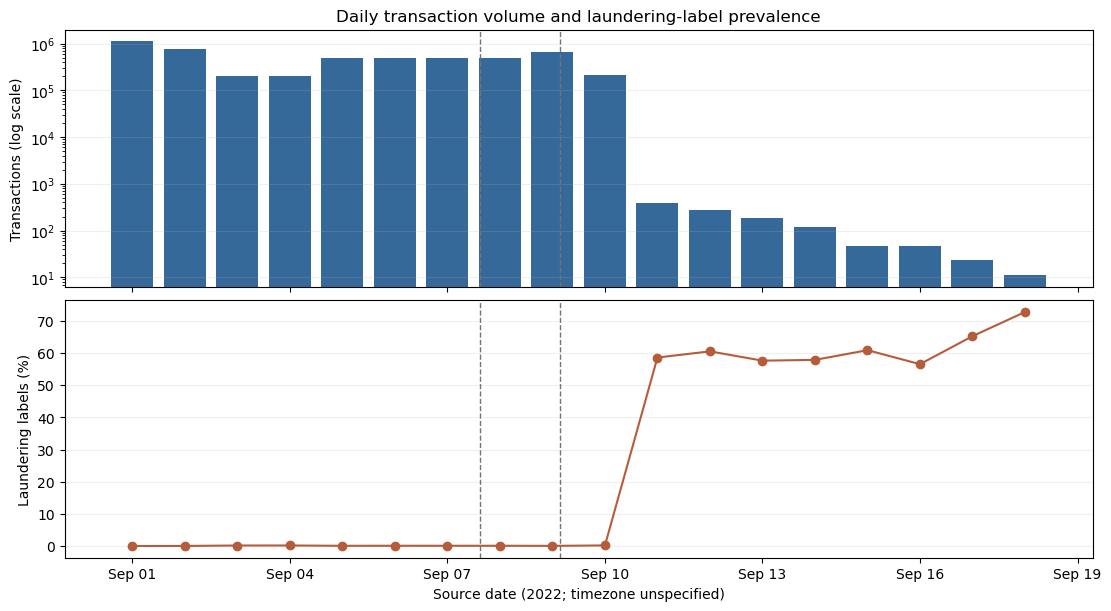

,timestamp,rows,positives,positive_rate
0,2022-09-01,1114919,322,0.000289
1,2022-09-02,754449,408,0.000541
2,2022-09-03,207382,391,0.001885
3,2022-09-04,207430,407,0.001962
4,2022-09-05,482650,471,0.000976
5,2022-09-06,482089,531,0.001101
6,2022-09-07,482750,497,0.001030
7,2022-09-08,482771,539,0.001116
8,2022-09-09,654463,514,0.000785
9,2022-09-10,208325,442,0.002122


Sep 11+ tail: 1,108 rows, 655 positives; 42.0% of test positives.
Pattern attempts spanning multiple splits: 140


In [34]:
daily = df.groupby(df["timestamp"].dt.floor("D"))["is_laundering"].agg(rows="size", positives="sum").reset_index()
daily["positive_rate"] = daily["positives"] / daily["rows"]
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
axes[0].bar(daily["timestamp"], daily["rows"], color="#35699a")
axes[0].set(yscale="log", ylabel="Transactions (log scale)", title="Daily transaction volume and laundering-label prevalence")
axes[1].plot(daily["timestamp"], daily["positive_rate"] * 100, marker="o", color="#b55c3b")
axes[1].set(ylabel="Laundering labels (%)", xlabel="Source date (2022; timezone unspecified)")
for axis in axes:
    for split_name, boundary in [("Validation", train_end), ("Test", validation_end)]:
        axis.axvline(df["timestamp"].iloc[boundary], color="0.45", linestyle="--", linewidth=1)
    axis.grid(axis="y", alpha=0.2)
axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=3))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.show()
display(daily)
late_tail = daily.loc[daily["timestamp"] >= "2022-09-11", ["rows", "positives"]].sum()
test_positives = split_summary.set_index("split").loc["test", "positives"]
print(f"Sep 11+ tail: {int(late_tail.rows):,} rows, {int(late_tail.positives):,} positives; "
      f"{late_tail.positives/test_positives:.1%} of test positives.")
known_pattern_rows = pattern_labels[pattern_labels["typology"].ne("UNKNOWN_UNLISTED")]
print("Pattern attempts spanning multiple splits:", int(known_pattern_rows.groupby("pattern_id")["split"].nunique().gt(1).sum()))

## 7. Export the four final CSV files
The three transaction files contain all 50 model inputs, provenance/graph identifiers, the timestamp and `is_laundering` target. `pattern_labels.csv` contains only positive-transaction evaluation annotations; an unlisted typology is explicitly unknown.

Feature definitions, preprocessing decisions, split counts and verification results are kept in this notebook. No separate nodes, agent, dictionary or manifest files are required.

In [35]:
output_columns = metadata_columns + ["amount_paid", "payment_currency", "amount_received",
    "receiving_currency", "payment_format", "is_laundering"] + transaction_features + historical_features
assert len(output_columns) == len(set(output_columns))
assert set(output_columns) == set(df.columns)
df = df[output_columns]
OUT.mkdir(parents=True, exist_ok=True)
for name, (start, end) in split_ranges.items():
    df.iloc[start:end].to_csv(OUT / f"{name}.csv", index=False, chunksize=50_000,
                            date_format="%Y-%m-%d %H:%M:%S")
    print(f"Saved {name}.csv: {end-start:,} rows")
pattern_labels.to_csv(OUT / "pattern_labels.csv", index=False)
print(f"Saved pattern_labels.csv: {len(pattern_labels):,} annotation rows")

Saved train.csv: 3,554,955 rows


Saved validation.csv: 761,746 rows


Saved test.csv: 761,635 rows
Saved pattern_labels.csv: 5,177 annotation rows


## 8. Validate the generated data
Validation checks saved files, not just in-memory tables. It compares every exported field against the prepared data, verifies source integrity and split isolation, checks evaluation-label coverage, and independently recomputes historical features from direct earlier-event filtering. The small causal fixtures also test tied timestamps, the 24-hour boundary, currencies, first-digit precision and future invariance.

### 8.1 Full exported-file checks

In [36]:
# Re-read every exported row; compare every field with the prepared data.
metadata_columns = ["tx_id", "source_row", "timestamp", "from_bank", "from_account",
                    "to_bank", "to_account", "src_account_id", "dst_account_id",
                    "src_node_id", "dst_node_id"]
text_columns = ["tx_id", "timestamp", "from_bank", "from_account", "to_bank", "to_account",
                "src_account_id", "dst_account_id", "payment_currency", "receiving_currency", "payment_format"]
assert len(feature_columns) == len(set(feature_columns)) == 50
assert len(numeric_features) == 47 and len(historical_features) == 32
assert set(historical_features) <= set(numeric_features) <= set(feature_columns)
assert list(split_ranges) == ["train", "validation", "test"]
assert not set(feature_columns) & set(metadata_columns + ["is_laundering"])
assert set(df.columns) == set(metadata_columns + feature_columns + ["is_laundering"])
assert not any("pattern" in c or "typology" in c for c in df.columns)
assert set(p.name for p in OUT.iterdir() if not p.name.startswith(".")) == {"train.csv", "validation.csv", "test.csv", "pattern_labels.csv"}

csv_dtypes = {c: "string[pyarrow]" for c in text_columns}
csv_dtypes.update({c: "float64" for c in numeric_features})
csv_dtypes.update({c: "int64" for c in ["source_row", "src_node_id", "dst_node_id", "is_laundering"]})
seen_source_rows = np.zeros(int(df.source_row.max()) + 1, dtype=bool)
split_validation, previous_split_end = [], None
for split_name, (start, stop) in split_ranges.items():
    checked, positives, last_time, last_source = 0, 0, None, None
    reader = pd.read_csv(OUT / f"{split_name}.csv", dtype=csv_dtypes, chunksize=200_000,
                         keep_default_na=False, float_precision="round_trip")
    for exported in reader:
        assert exported.columns.tolist() == df.columns.tolist(), "Unexpected CSV columns/order"
        assert not exported.isna().any().any(), "Missing value in exported data"
        assert np.isfinite(exported[numeric_features].to_numpy()).all(), "Nonfinite numeric feature"
        assert exported.is_laundering.isin([0, 1]).all(), "Invalid binary target"
        exported["timestamp"] = pd.to_datetime(exported.timestamp, format="%Y-%m-%d %H:%M:%S", errors="raise")
        expected = df.iloc[start + checked:start + checked + len(exported)]
        assert len(expected) == len(exported), "Extra exported records"
        for column in exported.columns:
            actual, original = exported[column].to_numpy(), expected[column].to_numpy()
            if column in numeric_features and original.dtype == np.float32:
                # CSV stores float32 features as decimal text; recover their original dtype.
                actual = actual.astype(np.float32)
            np.testing.assert_array_equal(actual, original, err_msg=f"{split_name}: {column}")
        source = exported.source_row.to_numpy()
        assert len(np.unique(source)) == len(source) and not seen_source_rows[source].any()
        assert exported.tx_id.eq(exported.source_row.map(lambda n: f"HI-Small:{n:08d}")).all()
        seen_source_rows[source] = True
        assert exported.timestamp.is_monotonic_increasing
        same_time = exported.timestamp.diff().eq(pd.Timedelta(0))
        assert exported.source_row.diff()[same_time].gt(0).all()
        if last_time is not None:
            assert exported.timestamp.iloc[0] > last_time or (
                exported.timestamp.iloc[0] == last_time and source[0] > last_source)
        elif previous_split_end is not None:
            assert exported.timestamp.iloc[0] > previous_split_end, "Timestamp shared across splits"
        assert exported.src_account_id.eq(exported.from_bank + ":" + exported.from_account).all()
        assert exported.dst_account_id.eq(exported.to_bank + ":" + exported.to_account).all()
        last_time, last_source = exported.timestamp.iloc[-1], source[-1]
        checked += len(exported)
        positives += int(exported.is_laundering.sum())
    assert checked == stop - start
    assert positives == int(df.iloc[start:stop].is_laundering.sum())
    previous_split_end = last_time
    split_validation.append({"split": split_name, "rows_checked": checked, "positives": positives})
    print(f"PASS {split_name}: all {checked:,} rows and all {len(df.columns)} fields match.")
assert int(seen_source_rows.sum()) == len(df)
assert sum(item["rows_checked"] for item in split_validation) == len(df)
validation_results = {"exported_rows_checked": len(df), "exported_columns_checked": len(df.columns),
                      "allowed_predictors": len(feature_columns), "csv_round_trip": "passed",
                      "unique_transaction_ids": "passed", "chronological_split_separation": "passed"}
display(pd.DataFrame(split_validation))

PASS train: all 3,554,955 rows and all 62 fields match.


PASS validation: all 761,746 rows and all 62 fields match.


PASS test: all 761,635 rows and all 62 fields match.


,split,rows_checked,positives
0,train,3554955,2856
1,validation,761746,760
2,test,761635,1561


### 8.2 Independent historical-feature checks

In [37]:
# Independent reference: filter earlier raw transactions directly, without the feature engine.
def reference_history(events, row):
    earlier = events[events.timestamp < row.timestamp]
    sender_out = earlier[earlier.src_node_id == row.src_node_id]
    sender_in = earlier[earlier.dst_node_id == row.src_node_id]
    receiver_out = earlier[earlier.src_node_id == row.dst_node_id]
    receiver_in = earlier[earlier.dst_node_id == row.dst_node_id]
    result = {}
    for prefix, outgoing, incoming in [("src", sender_out, sender_in), ("dst", receiver_out, receiver_in)]:
        result[prefix + "_hist_out_count"] = len(outgoing)
        result[prefix + "_hist_in_count"] = len(incoming)
        result[prefix + "_hist_out_degree"] = outgoing.dst_node_id.nunique()
        result[prefix + "_hist_in_degree"] = incoming.src_node_id.nunique()
    result["pair_hist_count"] = int(sender_out.dst_node_id.eq(row.dst_node_id).sum())
    result["reverse_pair_hist_count"] = int(receiver_out.dst_node_id.eq(row.src_node_id).sum())
    for prefix, direction, observations in [("src", "out", sender_out), ("dst", "in", receiver_in)]:
        stem = prefix + "_" + direction
        result[stem + "_count_24h"] = int(observations.timestamp.ge(row.timestamp - pd.Timedelta(days=1)).sum())
        times = observations.timestamp.drop_duplicates().sort_values()
        result[prefix + "_seconds_since_" + direction] = (row.timestamp - times.iloc[-1]).total_seconds() if len(times) else -1
        gaps = np.diff(times.to_numpy(dtype="datetime64[s]").astype(np.int64))
        result[stem + "_gap_count"] = len(gaps)
        result[stem + "_gap_mean_seconds"] = float(gaps.mean()) if len(gaps) else -1
        result[stem + "_burstiness"] = float((gaps.std() - gaps.mean()) / (gaps.std() + gaps.mean())) if len(gaps) >= 2 else 0
    benford = np.log10(1 + 1 / np.arange(1, 10))
    for prefix, observations, currency_column, amount_column in [
        ("src", sender_out, "payment_currency", "amount_paid"),
        ("dst", receiver_in, "receiving_currency", "amount_received"),
    ]:
        amounts = observations.loc[observations[currency_column].eq(getattr(row, currency_column)), amount_column]
        positive = amounts[amounts > 0]
        # Decimal text gives an independent leading-digit calculation, including tiny Bitcoin values.
        digits = [int(next(c for c in str(float(value)) if c in "123456789")) for value in positive]
        count, mean = len(digits), float(amounts.mean()) if len(amounts) else 0
        result[prefix + "_currency_hist_count"] = len(amounts)
        result[prefix + "_currency_benford_count"] = count
        result[prefix + "_currency_benford_valid"] = int(count >= 20)
        result[prefix + "_currency_benford_mad"] = float(np.abs(np.bincount(digits, minlength=10)[1:] / count - benford).mean()) if count >= 20 else -1
        result[prefix + "_currency_amount_mean"] = mean
        result[prefix + "_amount_to_hist_mean"] = float(getattr(row, amount_column) / mean) if mean > 0 else 0
    return result

history_sample = df.iloc[np.linspace(0, len(df) - 1, 100, dtype=np.int64)]
sampled_nodes = set(history_sample.src_node_id) | set(history_sample.dst_node_id)
history_input_columns = ["timestamp", "src_node_id", "dst_node_id", "payment_currency",
                         "receiving_currency", "amount_paid", "amount_received"]
# Keep every event involving a sampled node, including history before its split.
reference_events = df.loc[df.src_node_id.isin(sampled_nodes) | df.dst_node_id.isin(sampled_nodes), history_input_columns]
for row in history_sample.itertuples(index=False):
    expected = reference_history(reference_events, row)
    assert set(expected) == set(historical_features)
    for column, value in expected.items():
        np.testing.assert_allclose(getattr(row, column), value, rtol=2e-6, atol=1e-6,
                                   err_msg=f"{row.tx_id}: {column}")
validation_results.update({"historical_rows_recomputed": len(history_sample),
                           "historical_feature_comparisons": len(history_sample) * len(historical_features),
                           "independent_historical_checks": "passed"})
print("PASS: 100 actual transactions × 32 independently recomputed historical features.")
print("Sample rows with available Benford history:",
      int((history_sample.src_currency_benford_valid.eq(1) | history_sample.dst_currency_benford_valid.eq(1)).sum()))
del reference_events

PASS: 100 actual transactions × 32 independently recomputed historical features.
Sample rows with available Benford history: 41


### 8.3 Pattern labels and source integrity

In [38]:
# Evaluation annotations stay separate and must account for every original positive.
exported_patterns = pd.read_csv(OUT / "pattern_labels.csv", dtype="string[pyarrow]", keep_default_na=False)
assert exported_patterns.columns.tolist() == pattern_labels.columns.tolist()
np.testing.assert_array_equal(exported_patterns.to_numpy(), pattern_labels.astype("string").fillna("").to_numpy())
original_positive_ids = set(positive_raw.tx_id)
assert original_positive_ids == set(df.loc[df.is_laundering.eq(1), "tx_id"])
assert not exported_patterns[["tx_id", "pattern_id"]].duplicated().any()
assert set(exported_patterns.tx_id) == original_positive_ids
assert not exported_patterns.typology.eq("").any(), "Unlisted positives need an explicit unknown typology"
assert not {"typology", "pattern_ids", "pattern_id", "annotation_status"} & set(feature_columns)
expected_positive_splits = {}
for split_name, (start, stop) in split_ranges.items():
    part = df.iloc[start:stop]
    expected_positive_splits.update(dict.fromkeys(part.loc[part.is_laundering.eq(1), "tx_id"], split_name))
assert exported_patterns.split.eq(exported_patterns.tx_id.map(expected_positive_splits)).all()

import hashlib
def validation_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()
assert set(raw_source_hashes) == {"HI-Small_Trans.csv", "HI-Small_Patterns.txt"}
assert {name: validation_sha256(RAW_DIR / name) for name in raw_source_hashes} == raw_source_hashes
validation_results.update({"positive_labels_checked": exported_patterns.tx_id.nunique(),
                           "pattern_labels_separated": "passed", "original_sources_unchanged": "passed",
                           "status": "PASSED"})
display(pd.Series(validation_results, name="Validation result").to_frame())
print("The four CSVs are ready for the shared baseline, GNN and investigation workflow.")

,Validation result
exported_rows_checked,5078336
exported_columns_checked,62
allowed_predictors,50
csv_round_trip,passed
unique_transaction_ids,passed
chronological_split_separation,passed
historical_rows_recomputed,100
historical_feature_comparisons,3200
independent_historical_checks,passed
positive_labels_checked,5177


The four CSVs are ready for the shared baseline, GNN and investigation workflow.


## 9. Model inputs, target and metadata
### 9.1 Why 62 CSV columns contain 50 model features
**62 columns = 50 predictors (X) + 1 supervised target (y) + 11 metadata columns.**
The predictors are 47 numeric columns and 3 categorical columns. All 50 are available for modeling; categorical columns require training-fitted encoding or the chosen model's categorical handling. Encoded matrix width may differ from the source-column count.

| Role | Columns | How to use |
|---|---|---|
| Predictors (50) | Exactly `FEATURE_COLUMNS` in the next cell | Select the same names in the same order for train, validation and test. |
| Target (1) | `is_laundering` | Training supervision and validation/test evaluation; never part of X. |
| Provenance (2) | `tx_id`, `source_row` | Join predictions, alerts and original source rows; exclude from X. |
| Time (1) | `timestamp` | Split order and historical graph/evidence filtering; exclude the raw timestamp from X. Cyclic time features are already included. |
| Raw endpoint IDs (4) | `from_bank`, `from_account`, `to_bank`, `to_account` | Preserve exact strings for identity/lookup; exclude from X. |
| Composite account IDs (2) | `src_account_id`, `dst_account_id` | Identify bank-account endpoints; exclude from X. |
| Graph node indices (2) | `src_node_id`, `dst_node_id` | GNN graph connectivity, not scalar numeric predictors. |

`pattern_labels.csv` is a separate ground-truth annotation table. Its typologies, pattern IDs and annotation status never enter model inputs or agent evidence.

### 9.2 Explicit column lists
This cell can be copied into a model-training notebook without rerunning feature engineering. It uses an explicit allowlist, rather than selecting every CSV column except the target. The list preserves the predictor order used earlier in this notebook.

In [39]:
# Shared named columns for all three model datasets.
FEATURE_COLUMNS = [
    "amount_paid",
    "amount_received",
    "payment_currency",
    "receiving_currency",
    "payment_format",
    "log1p_amount_paid",
    "log1p_amount_received",
    "is_cross_bank",
    "is_self_transfer",
    "is_cross_currency",
    "is_crypto",
    "same_currency_amount_ratio",
    "same_currency_ratio_valid",
    "hour_sin",
    "hour_cos",
    "weekday_sin",
    "weekday_cos",
    "is_weekend",
    "src_hist_out_count",
    "src_hist_in_count",
    "dst_hist_out_count",
    "dst_hist_in_count",
    "src_hist_out_degree",
    "src_hist_in_degree",
    "dst_hist_out_degree",
    "dst_hist_in_degree",
    "pair_hist_count",
    "reverse_pair_hist_count",
    "src_out_count_24h",
    "dst_in_count_24h",
    "src_seconds_since_out",
    "dst_seconds_since_in",
    "src_out_gap_count",
    "dst_in_gap_count",
    "src_out_gap_mean_seconds",
    "dst_in_gap_mean_seconds",
    "src_out_burstiness",
    "dst_in_burstiness",
    "src_currency_hist_count",
    "dst_currency_hist_count",
    "src_currency_amount_mean",
    "dst_currency_amount_mean",
    "src_amount_to_hist_mean",
    "dst_amount_to_hist_mean",
    "src_currency_benford_count",
    "dst_currency_benford_count",
    "src_currency_benford_mad",
    "dst_currency_benford_mad",
    "src_currency_benford_valid",
    "dst_currency_benford_valid",
]
CATEGORICAL_COLUMNS = ["payment_currency", "receiving_currency", "payment_format"]
NUMERIC_COLUMNS = [c for c in FEATURE_COLUMNS if c not in CATEGORICAL_COLUMNS]
TARGET_COLUMN = "is_laundering"
METADATA_COLUMNS = [
    "tx_id",
    "source_row",
    "timestamp",
    "from_bank",
    "from_account",
    "to_bank",
    "to_account",
    "src_account_id",
    "dst_account_id",
    "src_node_id",
    "dst_node_id",
]
assert len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS)) == 50
assert len(NUMERIC_COLUMNS) == 47 and len(CATEGORICAL_COLUMNS) == 3
assert not set(FEATURE_COLUMNS) & set(METADATA_COLUMNS + [TARGET_COLUMN])
print("CSV columns: 50 predictors + 1 target + 11 metadata = 62.")


CSV columns: 50 predictors + 1 target + 11 metadata = 62.


### 9.3 Load the same predictors from each split
The following example reads only five rows per split to keep the notebook light. Remove `nrows=5` in the model owner's training code, or use chunked loading when appropriate. `X_train`, `X_validation` and `X_test` have the same 50 named columns in the same order; the categorical strings still need model-specific handling.

- **Baseline:** fit encoding/scaling and the model on training only, tune on validation, and freeze settings before final test evaluation.
- **GNN:** use `src_node_id` and `dst_node_id` to construct directed edges, and restrict history to `timestamp < target timestamp`. Do not append raw node numbers to the numeric feature vector.
- **Agent:** use transaction/identity fields after excluding `is_laundering`; never expose `pattern_labels.csv`. Restrict evidence by alert time or an explicit investigation cutoff.
- **Evaluation:** keep common split membership. Choose analyst-capacity k before test evaluation; disclose typology annotation coverage.

In [40]:
from pathlib import Path
import pandas as pd

MODEL_ROOT = Path.cwd()
if MODEL_ROOT.name == "notebooks":
    MODEL_ROOT = MODEL_ROOT.parent
DATA_DIR = MODEL_ROOT / "data" / "processed"
TEXT_COLUMNS = ["tx_id", "from_bank", "from_account", "to_bank", "to_account",
                "src_account_id", "dst_account_id"] + CATEGORICAL_COLUMNS
csv_dtypes = {column: "string" for column in TEXT_COLUMNS}
# Float32 is adequate for derived features; preserve original amounts as float64.
csv_dtypes.update({column: "float32" for column in NUMERIC_COLUMNS})
csv_dtypes.update({"amount_paid": "float64", "amount_received": "float64",
                   "same_currency_amount_ratio": "float64"})

samples, model_inputs, targets = {}, {}, {}
for split in ["train", "validation", "test"]:
    samples[split] = pd.read_csv(
        DATA_DIR / f"{split}.csv", nrows=5, dtype=csv_dtypes,
        parse_dates=["timestamp"], float_precision="round_trip")
    assert set(samples[split].columns) == set(FEATURE_COLUMNS + METADATA_COLUMNS + [TARGET_COLUMN])
    model_inputs[split] = samples[split][FEATURE_COLUMNS]
    targets[split] = samples[split][TARGET_COLUMN]
    assert model_inputs[split].columns.tolist() == FEATURE_COLUMNS
    print(f"{split}: X shape = {model_inputs[split].shape}; y shape = {targets[split].shape}")

X_train, y_train = model_inputs["train"], targets["train"]
X_validation, y_validation = model_inputs["validation"], targets["validation"]
X_test, y_test = model_inputs["test"], targets["test"]

# Graph structure and evidence remain available separately from the 50 predictors.
graph_edges_example = samples["train"][["tx_id", "src_node_id", "dst_node_id", "timestamp"]]
agent_evidence_example = samples["train"][METADATA_COLUMNS + [
    "amount_paid", "amount_received", "payment_currency", "receiving_currency", "payment_format"]]
assert TARGET_COLUMN not in X_train and TARGET_COLUMN not in agent_evidence_example
print("All three splits use the same 50-column input order.")

train: X shape = (5, 50); y shape = (5,)
validation: X shape = (5, 50); y shape = (5,)
test: X shape = (5, 50); y shape = (5,)
All three splits use the same 50-column input order.


The final outputs are suitable for the agreed streaming detection protocol. Important limitations remain: the data is synthetic, some positive transactions have no supplied typology, some attempts span splits, and the late test period has a markedly different label distribution. Benford deviation is exploratory and does not establish that an individual transaction is fraudulent.